# Ближайшие соседи и масштаб признаков

CC BY 4.0.

Выполняйте ячейки сверху вниз. Сначала решите задачи, затем обратитесь к решениям.

## Чему научимся

В игре появился новый герой. У него 650 единиц здоровья и 8 единиц магической силы. Можно ли по этим числам предположить, кто он: воин или маг?

В прошлом занятии наша модель давала всем один ответ. Теперь попробуем учитывать признаки: искать знакомых героев, похожих на нового.

После занятия вы сможете:

- Вычислять расстояния и предсказывать класс голосованием соседей.
- Объяснять, почему изменение масштаба признака может изменить прогноз.
- Проверять выбранное правило на новых примерах с известными ответами.

Пойдём по шагам: сравним героев вручную, изменим масштаб здоровья, устроим голосование и повторим опыт на Python.

## Карточки знакомых героев

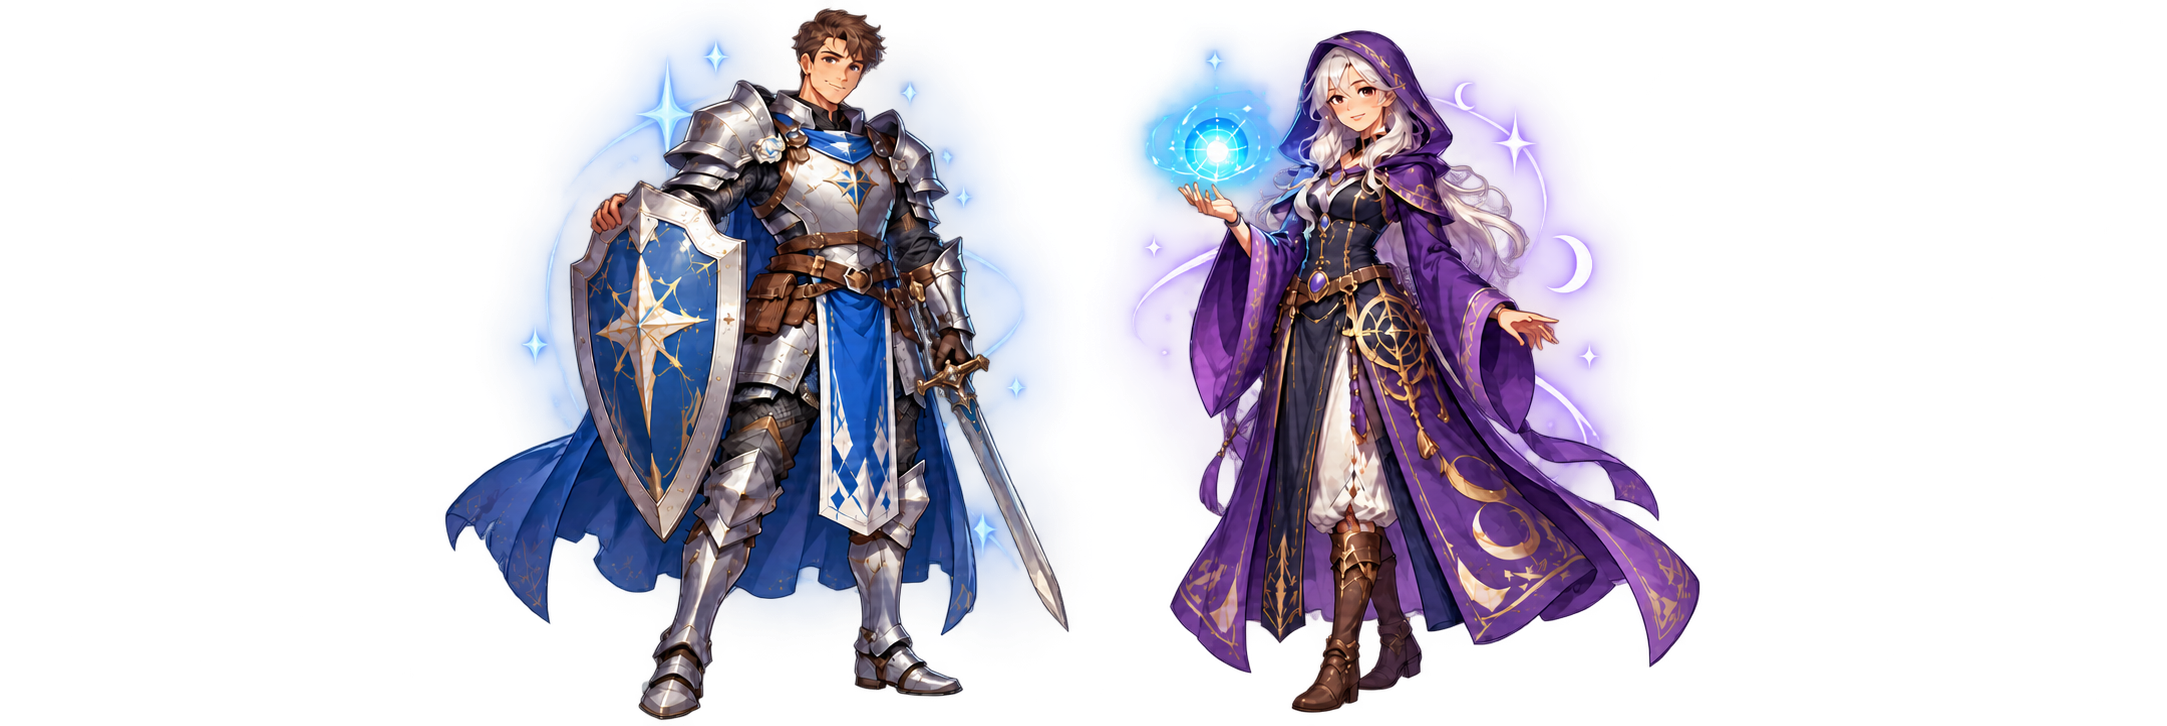

*Рисунок 1 — Воин и маг в задаче классификации*

Здоровье и магическая сила известны до прогноза. Класс — ответ, который хотим получить. Это задача классификации.

*Таблица 1 — Характеристики героев и их классы*

| Герой | Здоровье | Сила | Класс |
| --- | --- | --- | --- |
| А | 800 | 2 | воин |
| Б | 700 | 3 | воин |
| В | 300 | 9 | маг |
| Г | 400 | 8 | маг |
| Новый | 650 | 8 | неизвестен |

Четыре знакомые карточки — **обучающая часть**. Новый герой — запрос к модели; его класс пока скрыт. Названия А–Г признаками не служат.

Найдём самого похожего знакомого героя и возьмём его класс. Это **метод ближайшего соседа**: похожим по признакам объектам предсказываем одинаковый ответ.

## Что значит «похожий»?

Для одного числа расстояние — модуль разности. Между здоровьем 650 и 700 оно равно $|650-700|=50$. Модуль убирает знак: нас интересует величина отличия.

Для двух признаков сначала сложим их отличия. Обозначим здоровье через $h$, силу через $m$, а двух героев — через $a$ и $b$:

$$d(a,b)=|h_a-h_b|+|m_a-m_b|.$$

Такое расстояние называют **манхэттенским**. Посчитаем расстояние от нового героя до героя Б. У нового здоровье 650 и сила 8, у Б — здоровье 700 и сила 3:

1. Разница здоровья: $|650-700|=|-50|=50$.
2. Разница магической силы: $|8-3|=5$.
3. Складываем обе разницы:

$$d(\text{Новый},\text{Б})=|650-700|+|8-3|=50+5=55.$$

Так же считаем расстояния до остальных героев:

*Таблица 2 — Расстояния до нового героя в исходном масштабе*

| Герой | По здоровью | По силе | Сумма |
| --- | --- | --- | --- |
| А | 150 | 6 | 156 |
| Б | 50 | 5 | 55 |
| В | 350 | 1 | 351 |
| Г | 250 | 0 | 250 |

Минимальное расстояние у Б. Значит, один ближайший сосед предсказывает **«воин»**.

Можно измерять и по-другому: **евклидово расстояние** соответствует отрезку напрямую, как в теореме Пифагора:

$$d_E(a,b)=\sqrt{(h_a-h_b)^2+(m_a-m_b)^2}.$$

Например, для точек $(5,2)$ и $(8,6)$ манхэттенское расстояние равно $3+4=7$, а евклидово — $\sqrt{3^2+4^2}=5$. На рисунке оранжевый путь проходит вдоль координатных линий, а синий соединяет точки напрямую.



*Рисунок 2 — Манхэттенское и евклидово расстояния*

Эти способы измерения могут выбирать разных соседей. Дальше используем манхэттенское расстояние.

## Почему здоровье перевесило магию

У нового героя сила совпадает с силой мага Г. Однако по нашему правилу победил воин Б: отличия здоровья измеряются сотнями, а силы — единицами. Численно здоровье вносит гораздо больший вклад.

Представьте, что рост записали сначала в метрах, а затем в сантиметрах. Люди не выросли в сто раз, но числа стали в сто раз больше. Если просто складывать отличия, вклад роста тоже увеличится.

В нашей игре попробуем измерять здоровье **в сотнях единиц**: 800 станет 8, а 650 — 6,5. Для знакомых и нового героя используем одно преобразование. Расстояние теперь такое:

$$d(a,b)=\frac{|h_a-h_b|}{100}+|m_a-m_b|.$$

*Таблица 3 — Расстояния до нового героя после масштабирования здоровья*

| Герой | По здоровью | По силе | Сумма |
| --- | --- | --- | --- |
| А | 1,5 | 6 | 7,5 |
| Б | 0,5 | 5 | 5,5 |
| В | 3,5 | 1 | 4,5 |
| Г | 2,5 | 0 | 2,5 |

Теперь ближайший — Г, а прогноз — **«маг»**. На схеме те же карточки расположены от ближней к дальней для каждого масштаба.



*Рисунок 3 — Ближайшие соседи до и после масштабирования признака*

Мы выполнили **масштабирование признака**: изменили его числовой масштаб и тем самым его вклад в расстояние.

Удобный способ выбрать масштаб — **min–max нормализация**. Находим минимальное значение признака $x_{\min}$ и максимальное $x_{\max}$. Смотрим, насколько наше значение $x$ отстоит от нижней границы, и делим это расстояние на весь диапазон:

$$x_{\text{новое}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}}.$$

Числитель показывает расстояние от минимума до нашего значения, а знаменатель — расстояние между минимумом и максимумом. Так минимум превращается в 0, максимум — в 1, а значения между ними попадают в отрезок $[0,1]$.

Для здоровья наших четырёх героев минимум равен 300, максимум — 800. Весь диапазон составляет $800-300=500$. Здоровье нового героя преобразуется так:

$$\frac{650-300}{800-300}=\frac{350}{500}=0{,}7.$$

От минимума до нового героя — 70 % всего диапазона. На схеме меняются подписи шкалы, а порядок героев сохраняется.



*Рисунок 4 — Нормализация здоровья методом min–max*

Каждый признак нормализуют по своим границам. Для силы минимум равен 2, максимум — 9, поэтому сила нового героя 8 станет $\frac{8-2}{9-2}=\frac{6}{7}\approx0{,}86$. Минимумы и максимумы находим по обучающей части и затем используем для новых героев. Признак с одинаковыми значениями можно убрать: его диапазон равен нулю.

## Пусть соседи проголосуют

Один сосед может оказаться необычным или иметь ошибочную метку. Дадим слово нескольким: найдём **k ближайших соседей**, и пусть каждый проголосует за свой класс. Выберем класс с наибольшим числом голосов. Метод называют **KNN**, от английского *k-nearest neighbors*.

После изменения масштаба при $k=3$ это Г, В и Б: два мага и один воин. Прогноз — «маг». В исходных единицах тройка другая: Б, А, Г; там побеждает «воин».

Малое $k$ делает ответ чувствительным к отдельной карточке. Слишком большое включает далёких героев и может скрыть полезные различия. При двух классах нечётное число голосов исключает ничью.

При $k=4$ у нас ничья: два голоса против двух. Для примера с двумя классами удобно взять $k=3$, чтобы большинство определялось однозначно.

## Повторим на Python

Используем scikit-learn: `MinMaxScaler` выполнит нормализацию, а `KNeighborsClassifier` найдёт соседей и проведёт голосование. Библиотека входит в среду учебника.

Признаки и ответы храним отдельно. В каждой строке `X_train` стоят здоровье и сила одного героя; на той же позиции в `y_train` записан его класс. В `X_new` одна строка — новый герой.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

names = ["А", "Б", "В", "Г"]
X_train = [[800, 2], [700, 3], [300, 9], [400, 8]]
y_train = ["воин", "воин", "маг", "маг"]
X_new = [[650, 8]]


Нормализуем **оба признака** по формуле min–max. Вызов `fit_transform` находит границы по обучающим данным и преобразует их. Для нового героя вызываем `transform`: используем уже найденные границы.

In [ ]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_train)
X_new_scaled = scaler.transform(X_new)

print(X_scaled.round(3))
print(X_new_scaled.round(3))


У нового героя получатся признаки примерно $(0{,}7;\;0{,}857)$ — те же числа, которые мы нашли вручную. Метод `round(3)` округляет вывод до трёх знаков; в вычислениях остаются исходные значения.

Создадим модель с тремя соседями. `metric="manhattan"` задаёт манхэттенское расстояние. Вызов `fit` сохраняет обучающие примеры и их классы, а `predict` возвращает прогнозы для новых объектов.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3, metric="manhattan")
knn.fit(X_scaled, y_train)

prediction = knn.predict(X_new_scaled)
print("Класс нового героя:", prediction[0])


Получим «маг». Посмотрим, кто проголосовал: `kneighbors` возвращает расстояния и индексы соседей. Индекс — номер строки в обучающей таблице, начиная с нуля. Мы передали один новый объект, поэтому берём первую строку результатов.

In [ ]:
distances, indices = knn.kneighbors(X_new_scaled)
for distance, index in zip(distances[0], indices[0]):
    print(names[index], y_train[index], round(distance, 3))


Вывод: Г — маг, 0,5; Б — воин, примерно 0,814; В — маг, примерно 0,843. Два голоса за мага. После min–max порядок отличается от деления здоровья на 100: теперь мы изменили масштаб и здоровья, и силы.

## Попробуйте сами

1. Нормализуйте героя $(770,2)$ по границам обучающей таблицы и найдите ближайшего соседа вручную. Затем проверьте через `kneighbors`: для одного соседа передайте `n_neighbors=1`. Для самопроверки: признаки $(0{,}94;\;0)$, ближайший — А, расстояние 0,06.
2. Для исходного запроса сравните $k=1$ и $k=3$, меняя `n_neighbors` при создании модели. Затем сравните обучение на исходных и нормализованных признаках. Для самопроверки: при обоих $k$ исходные признаки дают «воин», min–max — «маг».
3. Верните $k=3$ и min–max нормализацию. Проверьте модель на трёх новых карточках ниже. Метрика — доля верных ответов из занятия 1.1.

*Таблица 4 — Новые герои для проверки классификатора*

| Герой | Здоровье | Сила | Ответ для проверки |
| --- | --- | --- | --- |
| Д | 770 | 2 | воин |
| Е | 350 | 9 | маг |
| Ж | 450 | 7 | маг |

Это тестовая часть. Преобразуем признаки тем же `scaler`, затем получим прогнозы. Метод `score` сравнивает их с известными классами и возвращает долю верных ответов.

In [ ]:
X_test = [[770, 2], [350, 9], [450, 7]]
y_test = ["воин", "маг", "маг"]
X_test_scaled = scaler.transform(X_test)

print("Прогнозы:", knn.predict(X_test_scaled))
print("Доля верных ответов:", knn.score(X_test_scaled, y_test))


Для самопроверки: прогнозы «воин», «маг», «маг», доля верных — $\frac{3}{3}=1$. Для выбора $k$ и способа масштабирования выделяют отдельную проверочную часть, а тест используют для итоговой оценки.

## Что стоит унести с собой

KNN отвечает по похожим обучающим примерам. Что считать похожим, определяют признаки, расстояние и масштаб. Число соседей определяет, кто голосует. А узнать, полезно ли всё правило, можно только по новым известным ответам.

## Самопроверка

### 1. Что передадим модели для нового героя?

A. Здоровье и магическую силу.<br>
B. Здоровье и правильный класс.<br>
C. Только название «Новый».<br>
D. Классы тестовых героев.

<details>
<summary>Подсказка</summary>

Какие свойства известны до предсказания?

</details>



### 2. Каковы манхэттенское и евклидово расстояния между $(5,2)$ и $(8,6)$?

A. 5 и 7.<br>
B. 7 и 5.<br>
C. 1 и 1.<br>
D. 25 и 49.

<details>
<summary>Подсказка</summary>

Разницы координат равны 3 и 4. В одном правиле складывают модули, в другом используют корень из суммы квадратов.

</details>



### 3. Кто ближайший к $(650,8)$ в исходных единицах при нашем манхэттенском расстоянии?

A. А, потому что у него больше здоровья.<br>
B. Г, потому что сила совпадает.<br>
C. Б, потому что расстояние 55 минимально.<br>
D. В, потому что он маг.

<details>
<summary>Подсказка</summary>

Сравните все четыре суммы, учитывая оба признака.

</details>



### 4. Здоровье всех героев разделили на 100. Чему равно расстояние от нового героя до Г?

A. 250.<br>
B. 25.<br>
C. 0.<br>
D. 2,5.

<details>
<summary>Подсказка</summary>

Посчитайте $\frac{|650-400|}{100}+|8-8|$.

</details>



### 5. Значение признака совпало с минимумом. Чему оно равно после min–max нормализации?

A. Нулю.<br>
B. Единице.<br>
C. Максимуму признака.<br>
D. Исходному минимуму.

<details>
<summary>Подсказка</summary>

Подставьте $x=x_{\min}$ в формулу нормализации при $x_{\max}>x_{\min}$.

</details>



### 6. После масштабирования при $k=3$ голосуют Г, В и Б. Какой прогноз?

A. «Воин»: Б ближе к новому герою, чем А.<br>
B. «Маг»: два голоса против одного.<br>
C. Ничья: всего четыре обучающих героя.<br>
D. Нужно сложить названия классов.

<details>
<summary>Подсказка</summary>

Голосуют только выбранные три соседа, каждый с одним голосом.

</details>



### 7. Почему для двух классов удобно взять $k=3$, а не $k=4$?

A. Чётное $k$ всегда запрещено.<br>
B. При трёх соседях расстояния не нужны.<br>
C. Три голоса не могут разделиться поровну между двумя классами.<br>
D. Три соседа всегда дают правильный ответ.

<details>
<summary>Подсказка</summary>

Во всей обучающей части два воина и два мага.

</details>



### 8. Модель хранит четыре обучающих примера. Можно ли предсказывать по пяти соседям?

A. Новый герой станет пятым соседом.<br>
B. Один сосед проголосует дважды.<br>
C. Библиотека молча возьмёт четыре карточки.<br>
D. Возникнет `ValueError`: обучающих карточек только четыре.

<details>
<summary>Подсказка</summary>

Сколько разных обучающих объектов доступно для голосования?

</details>



### 9. Метка ближайшего соседа ошибочна. Что возможно при $k=1$?

A. Ошибочная метка определит прогноз.<br>
B. KNN обязательно исправит метку.<br>
C. Все расстояния станут нулевыми.<br>
D. Масштабирование гарантированно устранит ошибку.

<details>
<summary>Подсказка</summary>

Сколько соседей участвует в таком решении?

</details>



### 10. На трёх тестовых карточках угаданы все классы. Какой вывод обоснован?

A. На любых новых героях ошибка будет нулевой.<br>
B. На этих трёх карточках доля верных ответов равна 1.<br>
C. Теперь можно подбирать $k$ по этим ответам и считать тот же тест итоговым.<br>
D. Настоящий класс исходного нового героя точно «маг».

<details>
<summary>Подсказка</summary>

На каких именно примерах измерен результат?

</details>




## Решения задач

### Задача 1

**A.** Оба признака доступны заранее. Правильный класс — искомый ответ, его использование было бы утечкой.

### Задача 2

**B.** $3+4=7$ и $\sqrt{9+16}=5$. Числа 25 и 49 — квадраты расстояний, а не сами расстояния.

### Задача 3

**C.** До Б расстояние 55. Совпадение одной силы у Г не отменяет разницу здоровья 250.

### Задача 4

**D.** Получаем $2{,}5+0=2{,}5$. Сила совпадает, но здоровье различается.

### Задача 5

**A.** $\frac{x_{\min}-x_{\min}}{x_{\max}-x_{\min}}=0$. Минимум становится нулём, а максимум — единицей.

### Задача 6

**B.** Г и В — маги, Б — воин. А в выбранную тройку не входит.

### Задача 7

**C.** При $k=3$ возможны результаты 3:0 и 2:1. При $k=4$ возможна ничья 2:2.

### Задача 8

**D.** Допустимо $1\leq k\leq4$. При попытке предсказать по пяти соседям `KNeighborsClassifier` выдаст `ValueError`.

### Задача 9

**A.** Голос единственного соседа решающий. Несколько соседей иногда помогают, но гарантии исправления нет.

### Задача 10

**B.** Мы проверили три конкретные карточки. Это не раскрывает класс другого героя и не обещает успех на любых данных; подбор настроек по тесту испортит независимость проверки.